# ⚽ Analyse exploratoire (EDA) — Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — ESEO, Python for Data Science

## Contexte et question

**Objectif du projet :** estimer quels clubs ont le plus de chances de remporter la **Ligue des Champions 2026-2027**.

**Rôle de cette EDA :** avant de construire un modèle, connaître nos données : ce qu'elles contiennent, si on peut leur faire confiance, ce qu'elles nous apprennent sur les matchs passés, et ce qu'elles ne permettent **pas** de conclure.

## Les données

| Table | Source | Une ligne = |
|---|---|---|
| `games.csv` | [Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores) (Kaggle) | un match (toutes compétitions) |
| `game_events.csv` | [Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores) (Kaggle) | un événement de match (but, carton, remplacement, tir au but) |
| `EloRatings.csv` | [Club Football Match Data](https://www.kaggle.com/datasets/adamgbor/club-football-match-data-2000-2025) (Kaggle) | le classement Elo d'un club à une date |

**L'Elo** est une note de niveau : un club gagne des points quand il gagne et en perd quand il perd. Battre une équipe forte rapporte beaucoup, battre une équipe faible rapporte peu. Plus l'Elo est haut, plus le club est fort **au moment présent**.

## Plan : les 4 questions de l'EDA
1. **Qu'ai-je ?** — structure des données
2. **Est-ce propre ?** — qualité
3. **Que se passe-t-il ?** — analyses utiles pour prédire
4. **Qu'est-ce qui manque ?** — limites

Puis une **conclusion** : 3 découvertes, 2 limites, 1 question à poursuivre.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.max_rows = 40
%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, VERT, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad'   # couleurs des graphiques

games = pd.read_csv('../data/games.csv')
elo = pd.read_csv('../data/EloRatings.csv')
events = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'type', 'club_id'])  # 3 colonnes utiles sur 11

print(f"games : {games.shape[0]:,} lignes × {games.shape[1]} colonnes")
print(f"elo : {elo.shape[0]:,} lignes × {elo.shape[1]} colonnes")
print(f"events : {events.shape[0]:,} lignes × {events.shape[1]} colonnes")

games : 88,958 lignes × 23 colonnes
elo : 273,972 lignes × 4 colonnes
events : 1,274,469 lignes × 3 colonnes


# 1. Qu'ai-je ? — Structure des données

## 1.1 Les matchs de Ligue des Champions

`games.csv` contient **toutes** les compétitions (championnats, coupes, Coupe du monde…). On ne garde que la Ligue des Champions (`competition_id == 'CL'`).

**Résultat :**
- **1 871 matchs**, de la saison 2012-2013 à la saison 2025-2026, avec **23 colonnes** : des entiers (buts, saison, identifiants), des décimaux (affluence) et du texte (clubs, phase, date) ;
- 125 matchs par saison jusqu'en 2023, puis **189** à partir de 2024 : c'est le nouveau format à 36 clubs ;
- 2019 n'en compte que 119 : la fin du tournoi s'est jouée en **matchs uniques** à Lisbonne (Covid) ;
- **attention :** `season` est l'année de **début** de saison. Arsenal–Atlético du 5 mai 2026 appartient à la saison `2025`.

In [2]:
ucl_games = games[games['competition_id'] == 'CL'].sort_values('date').copy()

print(f"Matchs de Ligue des Champions : {len(ucl_games):,} × {ucl_games.shape[1]} colonnes")
print(f"Types de colonnes : {ucl_games.dtypes.astype(str).value_counts().to_dict()}")
print(f"Matchs par saison : {ucl_games['season'].value_counts().sort_index().to_dict()}")

# 5 matchs pris au hasard (random_state fixe le hasard : mêmes lignes à chaque exécution)
colonnes = ['date', 'season', 'round', 'home_club_name', 'away_club_name', 'home_club_goals', 'away_club_goals']
ucl_games[colonnes].sample(5, random_state=42)

Matchs de Ligue des Champions : 1,871 × 23 colonnes
Types de colonnes : {'str': 14, 'int64': 6, 'float64': 3}
Matchs par saison : {2012: 125, 2013: 125, 2014: 125, 2015: 125, 2016: 125, 2017: 125, 2018: 125, 2019: 119, 2020: 125, 2021: 125, 2022: 125, 2023: 125, 2024: 189, 2025: 188}


,date,season,round,home_club_name,away_club_name,home_club_goals,away_club_goals
85871,2025-09-30,2025,Group Stage,Chelsea FC,SL Benfica,1,0
55960,2021-11-24,2021,Group C,Sporting CP,Borussia Dortmund,3,1
88517,2026-05-05,2025,Semi-Finals 2nd Leg,Arsenal FC,Atlético de Madrid,1,0
15398,2014-10-01,2014,Group A,Atlético de Madrid,Juventus FC,1,0
21148,2015-10-21,2015,Group A,Paris Saint-Germain,Real Madrid,0,0


## 1.2 La table Elo

**Résultat :**
- **une ligne = l'Elo d'un club à une date**, relevé deux fois par mois (le 1er et le 15) ;
- du 1er juillet 2000 au **1er septembre 2026**, soit juste avant la saison que l'on veut prédire ;
- 984 clubs, mais **seulement 19 pays** : pas d'Ukraine, de Croatie, de Suisse, de Tchéquie… Certains clubs de C1 n'auront donc pas d'Elo ;
- les noms ne sont pas écrits comme dans `games` (`Paris SG` / `Paris Saint-Germain`).

In [3]:
print(f"Période : du {elo['date'].min()} au {elo['date'].max()}")
print(f"Clubs : {elo['club'].nunique()} | Pays : {elo['country'].nunique()} → {sorted(elo['country'].unique())}")
elo.sample(5, random_state=42)

Période : du 2000-07-01 au 2026-09-01
Clubs : 984 | Pays : 19 → ['AUT', 'BEL', 'DEN', 'ENG', 'ESP', 'FIN', 'FRA', 'GER', 'GRE', 'ITA', 'NED', 'NOR', 'POL', 'POR', 'ROM', 'RUS', 'SCO', 'SWE', 'TUR']


,date,club,country,elo
176316,2018-06-15,Rapid Wien,AUT,1588.18
44450,2005-02-01,Le Havre,FRA,1473.31
249649,2025-09-01,Arles,FRA,1345.14
58709,2006-07-15,Pandurii,ROM,1341.98
34258,2004-01-15,Farul,ROM,1273.47


# 2. Est-ce propre ? — Qualité des données

## 2.1 Valeurs manquantes et piège du `dropna()`

**Résultat :**
- **aucun but et aucun nom de club ne manque** : les colonnes utiles pour prédire sont complètes ;
- les colonnes de classement (`*_position`) sont vides à **100 %** : elles concernent les championnats, pas la C1 ;
- l'affluence manque surtout en 2020 : ce sont les matchs **à huis clos** (Covid) ;
- les formations manquent pour toute la saison 2012.

**⚠️ Piège :** un `dropna()` supprimerait **tous** les matchs, puisque chaque ligne a au moins une case vide (les positions). On ne supprime jamais les valeurs manquantes à l'aveugle : on regarde d'abord **lesquelles** et **pourquoi**.

In [4]:
manquants = ucl_games.isna().sum()
manquants = manquants[manquants > 0]
print("Valeurs manquantes (% des matchs) :")
print((manquants / len(ucl_games) * 100).round(1).to_string())

print(f"\nAffluence manquante par saison : {ucl_games.loc[ucl_games['attendance'].isna(), 'season'].value_counts().sort_index().to_dict()}")
print(f"Matchs restants après dropna() : {len(ucl_games.dropna())} / {len(ucl_games)}")

Valeurs manquantes (% des matchs) :
home_club_position     100.0
away_club_position     100.0
stadium                  0.2
attendance               6.7
referee                  0.1
home_club_formation      6.7
away_club_formation      6.7

Affluence manquante par saison : {2014: 2, 2015: 1, 2016: 1, 2018: 1, 2019: 13, 2020: 103, 2021: 5}
Matchs restants après dropna() : 0 / 1871


## 2.2 Doublons et dates

**Résultat :** aucun doublon, et toutes les dates sont cohérentes avec leur saison. Un match de la saison `2015` a bien lieu en 2015 ou en 2016. La date, stockée en texte, est convertie en vraie date (`datetime`).

In [5]:
print(f"Matchs en double (même date, mêmes clubs) : {ucl_games.duplicated(['date', 'home_club_id', 'away_club_id']).sum()}")
print(f"Identifiants de match en double : {ucl_games['game_id'].duplicated().sum()}")

ucl_games['date'] = pd.to_datetime(ucl_games['date'])     # texte -> vraie date
annee = ucl_games['date'].dt.year
incoherents = (annee != ucl_games['season']) & (annee != ucl_games['season'] + 1)
print(f"Dates incohérentes avec la saison : {incoherents.sum()}")

Matchs en double (même date, mêmes clubs) : 0
Identifiants de match en double : 0
Dates incohérentes avec la saison : 0


## 2.3 Des scores faux : les tirs au but comptés comme des buts

**Constat :** certains scores sont anormaux. Atlético–PSV (2016) est noté **8-7**, alors que le match s'est terminé **0-0** et a été décidé aux tirs au but.

**Méthode :** on croise avec `game_events.csv`.
- Les événements `Shootout` donnent les matchs avec une séance de tirs au but.
- Les événements `Goals` donnent les **vrais** buts de chaque club.

**Résultat :**
- les deux sources donnent le même score pour **1 863 matchs**, et ne diffèrent **que** pour les **8 matchs avec tirs au but** ;
- on corrige donc ces 8 scores avec le recomptage, et on garde l'information dans une colonne `tirs_au_but`.

**Impact :** ces 8 matchs étaient comptés comme des victoires alors que ce sont des nuls. Le Real Madrid en avait 3 : après correction, **le Bayern passe devant le Real** au nombre de victoires.

In [6]:
events_cl = events[events['game_id'].isin(ucl_games['game_id'])]
matchs_tab = events_cl.loc[events_cl['type'] == 'Shootout', 'game_id'].unique()

# Vrais buts de chaque club : on compte les événements "Goals" par (match, club)
buts = events_cl[events_cl['type'] == 'Goals'].groupby(['game_id', 'club_id']).size()
buts_dom = buts.reindex(list(zip(ucl_games['game_id'], ucl_games['home_club_id'])), fill_value=0).to_numpy()
buts_ext = buts.reindex(list(zip(ucl_games['game_id'], ucl_games['away_club_id'])), fill_value=0).to_numpy()

differents = (buts_dom != ucl_games['home_club_goals']) | (buts_ext != ucl_games['away_club_goals'])
print(f"Matchs avec tirs au but : {len(matchs_tab)}")
print(f"Matchs dont le score ne correspond pas aux buts : {differents.sum()} "
      f"(dont avec tirs au but : {ucl_games.loc[differents, 'game_id'].isin(matchs_tab).sum()})")

# Tableau avant / après, puis correction
comparaison = ucl_games.loc[differents, ['date', 'home_club_name', 'away_club_name']].copy()
comparaison['score_enregistre'] = (ucl_games.loc[differents, 'home_club_goals'].astype(str) + '-'
                                   + ucl_games.loc[differents, 'away_club_goals'].astype(str))
ucl_games['tirs_au_but'] = ucl_games['game_id'].isin(matchs_tab)
ucl_games['home_club_goals'] = buts_dom
ucl_games['away_club_goals'] = buts_ext
comparaison['score_reel'] = (ucl_games.loc[differents, 'home_club_goals'].astype(str) + '-'
                             + ucl_games.loc[differents, 'away_club_goals'].astype(str))
comparaison

Matchs avec tirs au but : 8
Matchs dont le score ne correspond pas aux buts : 8 (dont avec tirs au but : 8)


,date,home_club_name,away_club_name,score_enregistre,score_reel
16359,2015-03-17,Atlético de Madrid,Bayer 04 Leverkusen,4-2,1-0
22292,2016-03-15,Atlético de Madrid,PSV Eindhoven,8-7,0-0
22959,2016-05-28,Real Madrid,Atlético de Madrid,6-4,1-1
68775,2024-03-12,Arsenal FC,FC Porto,4-2,1-0
68778,2024-03-13,Atlético de Madrid,Inter Milan,5-3,2-1
69137,2024-04-17,Manchester City,Real Madrid,4-5,1-1
78492,2025-03-11,Liverpool FC,Paris Saint-Germain,1-5,0-1
78513,2025-03-12,Atlético de Madrid,Real Madrid,3-4,1-0


## 2.4 Des noms de phases incohérents

**Constat :** la colonne `round` contient **24 noms** pour **7 phases** réelles : majuscules différentes (`last 16 1st leg` / `Last 16 1st Leg`), groupes détaillés (`Group A`…). Surtout, depuis 2024, `Group Stage` désigne la nouvelle **phase de ligue**, qui n'a plus de groupes.

**Correction :** on crée une colonne `phase` propre. Le tableau saison × phase sert de vérification : chaque saison a bien 1 finale, 4 demies, etc.

**Ce qu'il montre :** 2019 n'a que 4 quarts et 2 demies (matchs uniques, Covid), et **2025 n'a pas de finale** : les données s'arrêtent aux demi-finales (6 mai 2026).

In [7]:
r = ucl_games['round'].str.lower()
conditions = [                                    # la 1re condition vraie l'emporte
    r.str.startswith('group') & (ucl_games['season'] >= 2024),
    r.str.startswith('group'),
    r.str.startswith('intermediate'),
    r.str.startswith('last 16'),
    r.str.startswith('quarter'),
    r.str.startswith('semi'),
    r == 'final',
]
phases = ['Phase de ligue', 'Phase de groupes', 'Barrages', 'Huitièmes', 'Quarts', 'Demies', 'Finale']
ucl_games['phase'] = np.select(conditions, phases, default='Inconnue')

print(f"{ucl_games['round'].nunique()} noms dans 'round' → {ucl_games['phase'].nunique()} phases "
      f"(non reconnus : {(ucl_games['phase'] == 'Inconnue').sum()})")
pd.crosstab(ucl_games['season'], ucl_games['phase'])[phases]

24 noms dans 'round' → 7 phases (non reconnus : 0)


phase,Phase de ligue,Phase de groupes,Barrages,Huitièmes,Quarts,Demies,Finale
season,,,,,,,
2012,0,96,0,16,8,4,1
2013,0,96,0,16,8,4,1
2014,0,96,0,16,8,4,1
2015,0,96,0,16,8,4,1
2016,0,96,0,16,8,4,1
2017,0,96,0,16,8,4,1
2018,0,96,0,16,8,4,1
2019,0,96,0,16,4,2,1
2020,0,96,0,16,8,4,1


# 3. Que se passe-t-il ? — Ce qui influence le résultat d'un match

## 3.1 Répartition des résultats

**Question :** quelle est la probabilité de chaque résultat ?

**Résultat :** **47,6 %** de victoires à domicile, **20,0 %** de nuls et **32,4 %** de victoires à l'extérieur.

**Ce que ça veut dire :** la règle « l'équipe à domicile gagne » a raison dans 47,6 % des cas. C'est la première **référence à battre** pour un modèle.

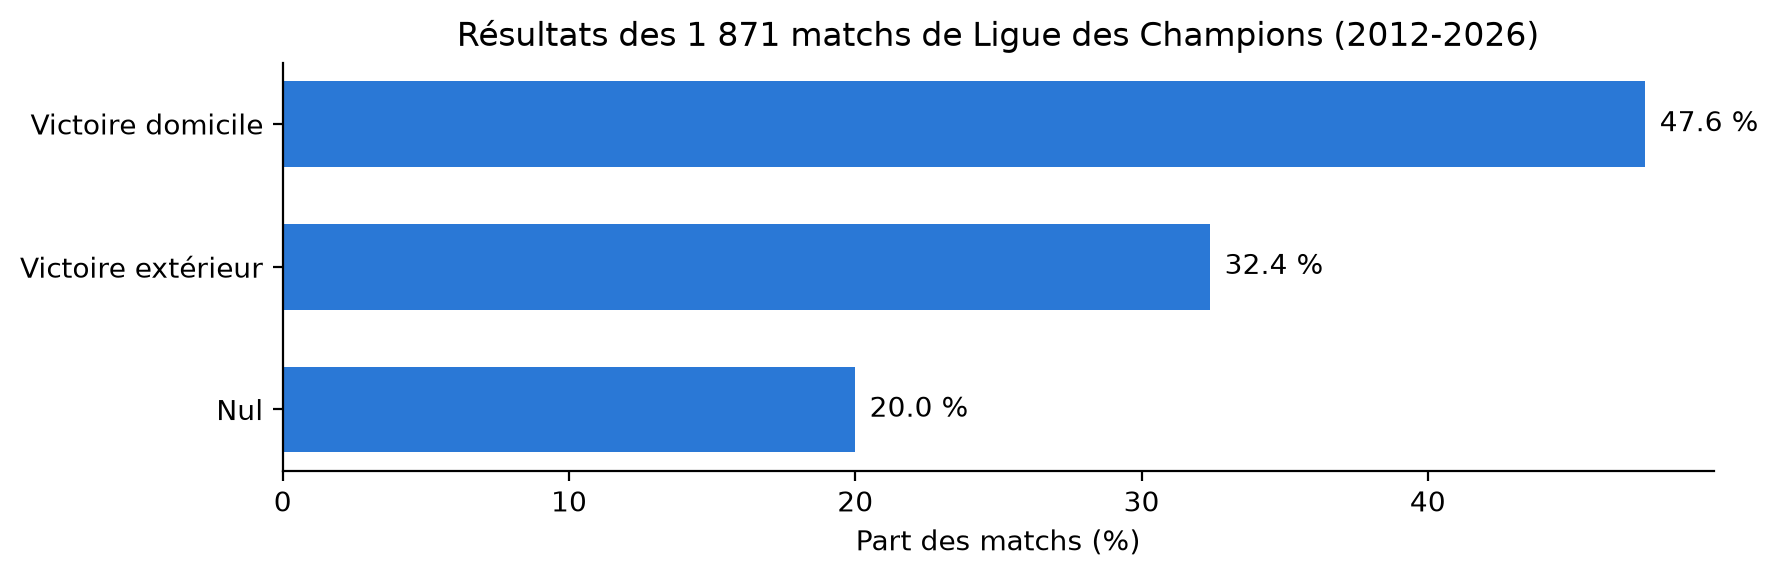

In [8]:
ucl_games['resultat'] = np.select(
    [ucl_games['home_club_goals'] > ucl_games['away_club_goals'],
     ucl_games['home_club_goals'] < ucl_games['away_club_goals']],
    ['Victoire domicile', 'Victoire extérieur'],
    default='Nul',
)
repartition = ucl_games['resultat'].value_counts(normalize=True).mul(100).round(1)

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(repartition.index, repartition.values, color=BLEU, height=0.6)
for y, valeur in enumerate(repartition.values):
    ax.text(valeur + 0.5, y, f"{valeur:.1f} %", va='center')
ax.invert_yaxis()
ax.set_xlabel('Part des matchs (%)')
ax.set_title('Résultats des 1 871 matchs de Ligue des Champions (2012-2026)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3.2 Hypothèse : l'avantage du terrain vient du public

**Test :** en **2020-2021**, les matchs se sont joués **à huis clos** à cause du Covid. Si l'hypothèse est vraie, l'avantage du terrain doit disparaître cette saison-là.

**Résultat :** d'habitude, l'équipe à domicile marque **0,2 à 0,6 but de plus** que l'équipe à l'extérieur. En 2020-2021, l'écart tombe à **0,00**. Il revient dès le retour du public.

**Interprétation :** les données vont dans le sens de l'hypothèse.

**⚠️ Limites :** c'est une seule saison (125 matchs), sans test statistique, et d'autres choses ont changé cette année-là (calendrier serré, 5 remplacements). En 2019-2020, une partie des matchs s'est jouée sur terrain neutre (Lisbonne), ce qui réduit aussi l'écart.

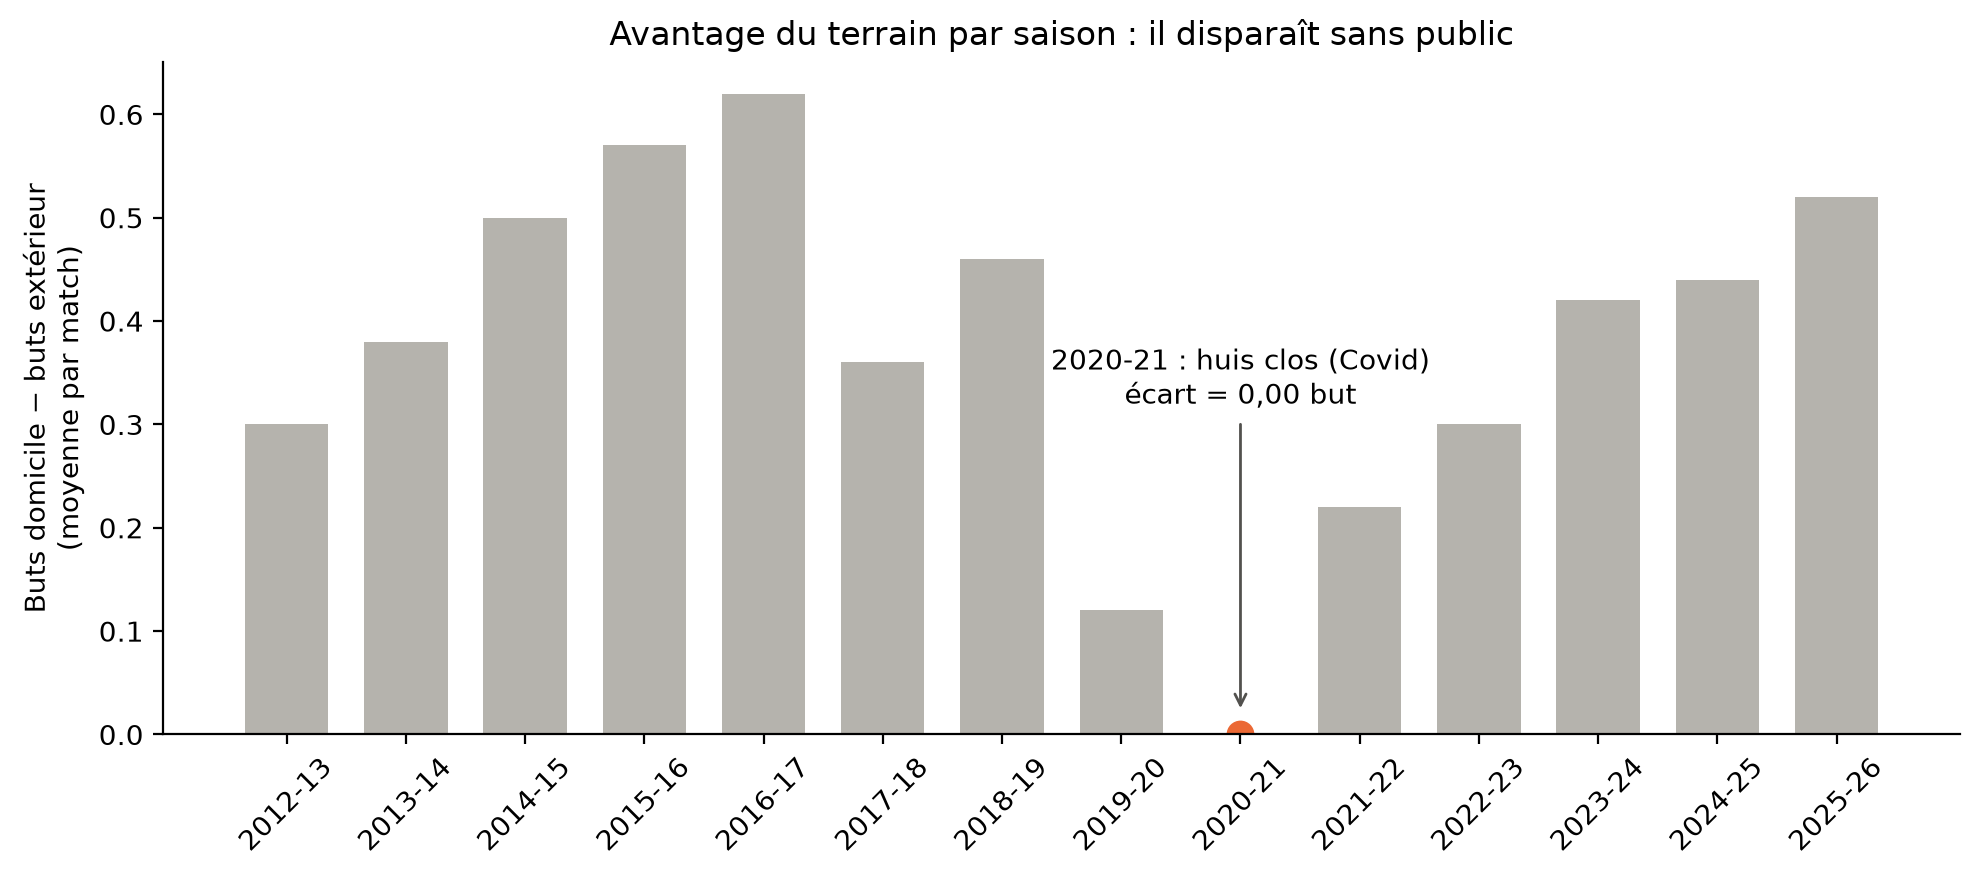

In [9]:
ucl_games['ecart_buts'] = ucl_games['home_club_goals'] - ucl_games['away_club_goals']
par_saison = ucl_games.groupby('season')['ecart_buts'].mean().round(2)

couleurs = [ORANGE if saison == 2020 else GRIS for saison in par_saison.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(par_saison.index, par_saison.values, color=couleurs, width=0.7)
ax.plot(2020, 0, marker='o', markersize=9, color=ORANGE)   # la barre vaut 0 : on la marque d'un point
ax.annotate('2020-21 : huis clos (Covid)\nécart = 0,00 but', xy=(2020, 0.02), xytext=(2020, 0.32),
            ha='center', arrowprops=dict(arrowstyle='->', color='#52514e'))
ax.set_xticks(par_saison.index)
ax.set_xticklabels([f"{s}-{str(s + 1)[2:]}" for s in par_saison.index], rotation=45)
ax.set_ylabel('Buts domicile − buts extérieur\n(moyenne par match)')
ax.set_title("Avantage du terrain par saison : il disparaît sans public")
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3.3 Quels clubs gagnent le plus souvent ?

Compter les victoires avantage les clubs qui jouent beaucoup de matchs. On calcule donc un **taux de victoire**, pour les clubs qui ont au moins 30 matchs.

**Résultat :** le **Bayern** (69 %) devance le **Real Madrid** (64 %). **Arsenal** est 5ᵉ (58 %) avec deux fois moins de matchs que le Real.

**⚠️ Limite :** c'est une moyenne sur 14 saisons. Elle mesure la régularité **passée** d'un club, pas son niveau **actuel**.

In [10]:
dom = pd.DataFrame({'club': ucl_games['home_club_name'], 'victoire': ucl_games['resultat'] == 'Victoire domicile'})
ext = pd.DataFrame({'club': ucl_games['away_club_name'], 'victoire': ucl_games['resultat'] == 'Victoire extérieur'})

par_club = pd.concat([dom, ext]).groupby('club').agg(matchs=('victoire', 'size'), victoires=('victoire', 'sum'))
par_club['taux_victoire'] = (par_club['victoires'] / par_club['matchs'] * 100).round(1)
par_club[par_club['matchs'] >= 30].sort_values('taux_victoire', ascending=False).head(10)

,matchs,victoires,taux_victoire
club,,,
Bayern Munich,160,111,69.4
Real Madrid,170,109,64.1
Liverpool FC,93,56,60.2
FC Barcelona,142,85,59.9
Arsenal FC,78,45,57.7
Paris Saint-Germain,148,84,56.8
Manchester City,139,77,55.4
Chelsea FC,93,49,52.7
Juventus FC,120,61,50.8


## 3.4 Relier chaque match à l'Elo des deux clubs

**Problème :** les noms diffèrent entre les tables. On écrit donc une **table de correspondance** à la main, vérifiée club par club. Par exemple, `Red Star` dans la table Elo est le Red Star **de Paris**, pas l'Étoile rouge de Belgrade : on ne l'a pas relié.

**Quel Elo prendre ?** Pour chaque match, le **dernier Elo publié avant le jour du match** (`merge_asof`). Prendre un Elo publié après le match serait de la triche : il contiendrait déjà le résultat (**fuite d'information**).

**Résultat :** **84 clubs sur 106** sont reliés. Les 22 autres viennent de pays absents de la table Elo. **80 %** des matchs ont l'Elo des deux équipes.

In [11]:
correspondance = {   # nom dans games -> nom dans elo
    'Arsenal FC': 'Arsenal', 'Aston Villa': 'Aston Villa', 'Chelsea FC': 'Chelsea', 'Leicester City': 'Leicester',
    'Liverpool FC': 'Liverpool', 'Manchester City': 'Man City', 'Manchester United': 'Man United',
    'Newcastle United': 'Newcastle', 'Tottenham Hotspur': 'Tottenham',
    'Athletic Bilbao': 'Ath Bilbao', 'Atlético de Madrid': 'Ath Madrid', 'FC Barcelona': 'Barcelona',
    'Girona FC': 'Girona', 'Málaga CF': 'Malaga', 'Real Madrid': 'Real Madrid', 'Real Sociedad': 'Sociedad',
    'Sevilla FC': 'Sevilla', 'Valencia CF': 'Valencia', 'Villarreal CF': 'Villarreal',
    '1.FC Union Berlin': 'Union Berlin', 'Bayer 04 Leverkusen': 'Leverkusen', 'Bayern Munich': 'Bayern Munich',
    'Borussia Dortmund': 'Dortmund', 'Borussia Mönchengladbach': 'MGladbach', 'Eintracht Frankfurt': 'Ein Frankfurt',
    'FC Schalke 04': 'Schalke 04', 'RB Leipzig': 'RB Leipzig', 'TSG 1899 Hoffenheim': 'Hoffenheim',
    'VfB Stuttgart': 'Stuttgart', 'VfL Wolfsburg': 'Wolfsburg',
    'AC Milan': 'Milan', 'Associazione Sportiva Roma': 'Roma', 'Atalanta BC': 'Atalanta',
    'Bologna Football Club 1909': 'Bologna', 'Inter Milan': 'Inter', 'Juventus FC': 'Juventus',
    'SSC Napoli': 'Napoli', 'Società Sportiva Lazio S.p.A.': 'Lazio',
    'AS Monaco': 'Monaco', 'LOSC Lille': 'Lille', 'Montpellier HSC': 'Montpellier', 'Olympique Lyon': 'Lyon',
    'Olympique Marseille': 'Marseille', 'Paris Saint-Germain': 'Paris SG', 'RC Lens': 'Lens',
    'Stade Brestois 29': 'Brest', 'Stade Rennais FC': 'Rennes',
    'Ajax Amsterdam': 'Ajax', 'Feyenoord Rotterdam': 'Feyenoord', 'PSV Eindhoven': 'PSV Eindhoven',
    'FC Porto': 'Porto', 'SC Braga': 'Sp Braga', 'SL Benfica': 'Benfica', 'Sporting CP': 'Sp Lisbon',
    'Club Brugge KV': 'Club Brugge', 'KAA Gent': 'Gent', 'KRC Genk': 'Genk', 'RSC Anderlecht': 'Anderlecht',
    'Royal Antwerp FC': 'Antwerp', 'Union Saint-Gilloise': 'St. Gilloise',
    'Austria Vienna': 'Austria Wien', 'Fußballclub Red Bull Salzburg': 'Salzburg',
    'Sportklub Puntigamer Sturm Graz': 'Sturm Graz', 'Celtic FC': 'Celtic', 'Rangers FC': 'Rangers',
    'FC Copenhagen': 'FC Kobenhavn', 'FC Midtjylland': 'Midtjylland', 'FC Nordsjaelland': 'Nordsjaelland',
    'Athlitiki Enosi Konstantinoupoleos': 'AEK', 'Olympiakos Syndesmos Filathlon Peiraios': 'Olympiakos',
    'Basaksehir FK': 'Buyuksehyr', 'Beşiktaş Jimnastik Kulübü': 'Besiktas', 'Galatasaray': 'Galatasaray',
    'AO FK Zenit Sankt-Peterburg': 'Zenit', 'FK Krasnodar': 'FC Krasnodar', 'FK Rostov': 'Rostov',
    'FK Spartak Moskva': 'Spartak Moskva', 'PFK CSKA Moskva': 'CSKA Moskva',
    'Футбольный клуб "Локомотив" Москва': 'Lok Moskva',
    'CFR Cluj': 'CFR Cluj', 'FCSB': 'Steaua', 'Legia Warszawa': 'Legia',
    'Fotballklubben Bodø/Glimt': 'Bodoe Glimt', 'Malmö Fotbollförening': 'Malmoe',
}
assert all(nom in set(elo['club']) for nom in correspondance.values())   # pas de faute de frappe

# Pour chaque match : le dernier Elo publié AVANT le jour du match, pour chaque club
elo['date'] = pd.to_datetime(elo['date'])
elo_trie = elo.sort_values('date')[['date', 'club', 'elo']]
matchs_elo = ucl_games.copy()
matchs_elo['home_elo_name'] = matchs_elo['home_club_name'].map(correspondance)
matchs_elo['away_elo_name'] = matchs_elo['away_club_name'].map(correspondance)
for cote in ['home', 'away']:
    matchs_elo = pd.merge_asof(
        matchs_elo, elo_trie.rename(columns={'club': f'{cote}_elo_name', 'elo': f'{cote}_elo'}),
        on='date', by=f'{cote}_elo_name', allow_exact_matches=False)

avec_elo = matchs_elo.dropna(subset=['home_elo', 'away_elo']).copy()
clubs_c1 = set(ucl_games['home_club_name']) | set(ucl_games['away_club_name'])
print(f"Clubs reliés : {len(correspondance)} / {len(clubs_c1)}")
print(f"Matchs avec l'Elo des deux clubs : {len(avec_elo)} / {len(matchs_elo)} ({len(avec_elo) / len(matchs_elo):.0%})")
print(f"Clubs sans Elo : {sorted(clubs_c1 - set(correspondance))}")

Clubs reliés : 84 / 106
Matchs avec l'Elo des deux clubs : 1500 / 1871 (80%)
Clubs sans Elo : ['AC Sparta Prague', 'APOEL Nicosia', 'BATE Borisov', 'BSC Young Boys', 'Dynamo Kyiv', 'FC Astana', 'FC Basel 1893', 'FC Shakhtar Donetsk', 'FC Sheriff Tiraspol', 'FC Viktoria Plzen', 'Ferencvárosi TC', 'GNK Dinamo Zagreb', 'Kairat Almaty', 'Ludogorets Razgrad', 'Maccabi Haifa', 'Maccabi Tel Aviv', 'NK Maribor', 'Pafos FC', 'Qarabağ FK', 'Red Star Belgrade', 'SK Slavia Prague', 'Slovan Bratislava']


## 3.5 Hypothèse : l'équipe au meilleur Elo gagne plus souvent

**Test :** on compare deux règles simples, sur les matchs où l'on connaît les deux Elo :
- « l'équipe à domicile gagne » ;
- « l'équipe avec le meilleur Elo (le favori) gagne ».

**Résultat :**
- la règle Elo a raison dans **56 %** des matchs, contre **48 %** pour la règle domicile ;
- le favori gagne **40 %** des matchs quand l'écart d'Elo est faible (moins de 50 points), et **79 %** quand l'écart dépasse 300 points.

**Interprétation :** hypothèse confirmée. L'écart d'Elo est la variable la plus utile trouvée jusqu'ici, et notre futur modèle devra **faire mieux que 56 %** pour servir à quelque chose.

**⚠️ Limites :** une règle « qui gagne » ne prédit jamais de nul, alors qu'il y en a 20 %. Et une corrélation n'est pas une cause : l'Elo **résume** le niveau d'une équipe, il ne la fait pas gagner.

Règle « domicile gagne »    : 47.7% de bonnes prédictions
Règle « meilleur Elo gagne » : 56.3% de bonnes prédictions


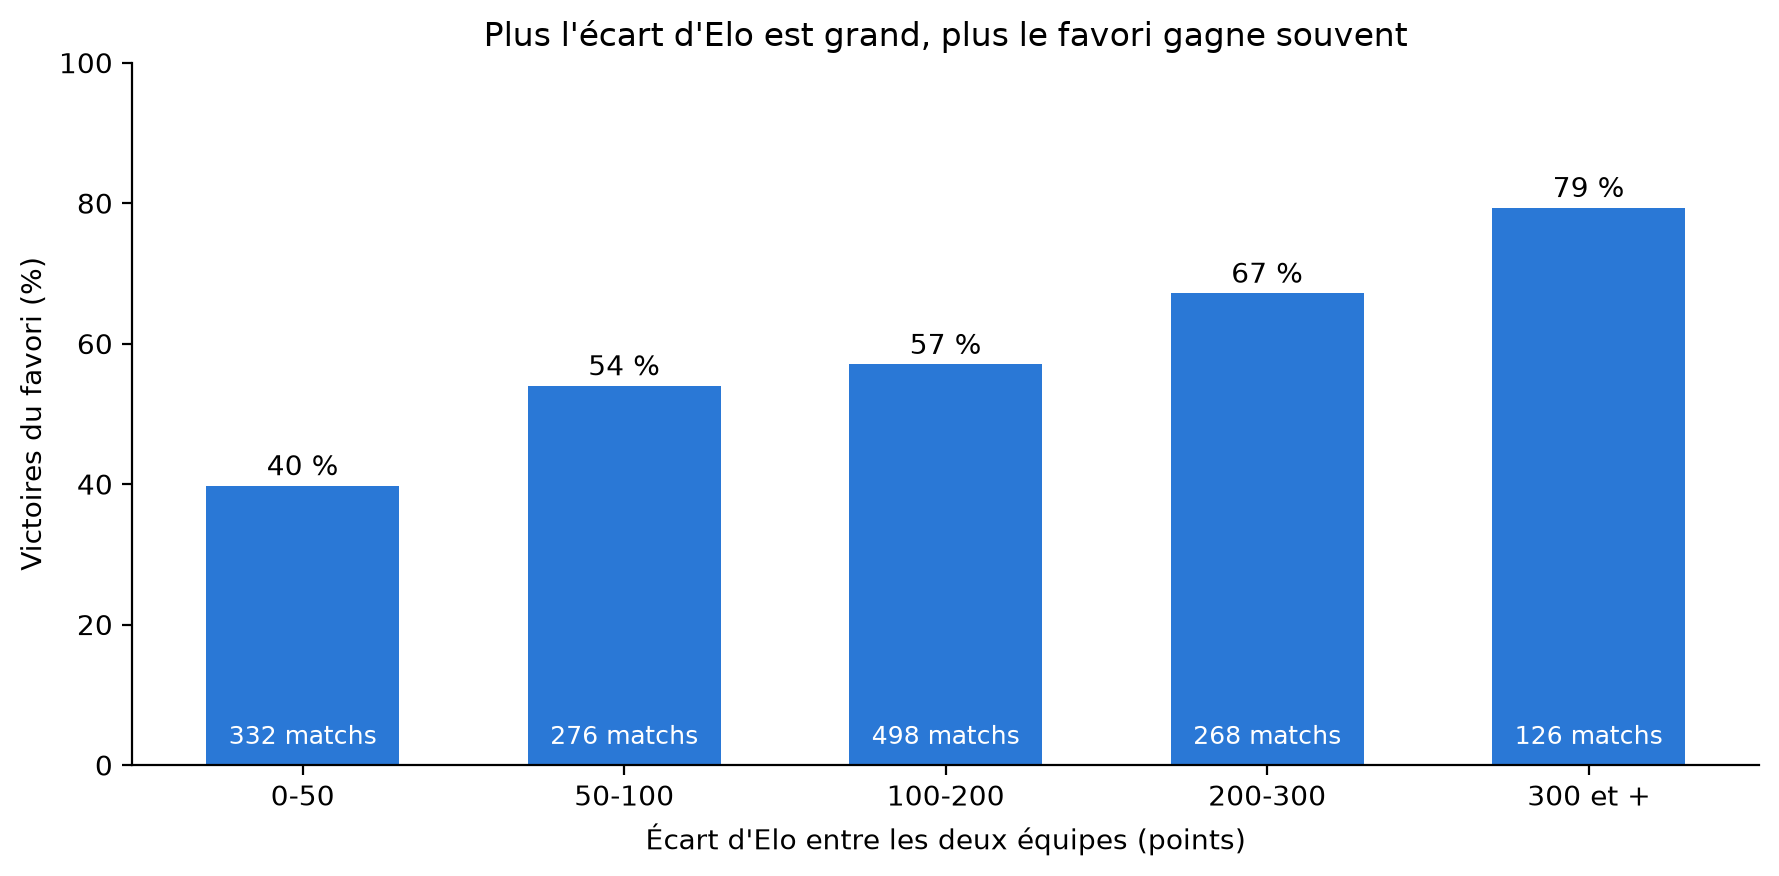

In [12]:
avec_elo['ecart_elo'] = avec_elo['home_elo'] - avec_elo['away_elo']
favori_domicile = avec_elo['ecart_elo'] > 0
avec_elo['favori_gagne'] = ((favori_domicile & (avec_elo['resultat'] == 'Victoire domicile'))
                            | (~favori_domicile & (avec_elo['resultat'] == 'Victoire extérieur')))

print(f"Règle « domicile gagne »    : {(avec_elo['resultat'] == 'Victoire domicile').mean():.1%} de bonnes prédictions")
print(f"Règle « meilleur Elo gagne » : {avec_elo['favori_gagne'].mean():.1%} de bonnes prédictions")

# Victoires du favori selon l'écart d'Elo
avec_elo['tranche'] = pd.cut(avec_elo['ecart_elo'].abs(), bins=[0, 50, 100, 200, 300, 1000],
                             labels=['0-50', '50-100', '100-200', '200-300', '300 et +'], include_lowest=True)
par_tranche = avec_elo.groupby('tranche', observed=True)['favori_gagne'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(par_tranche.index.astype(str), par_tranche['mean'] * 100, color=BLEU, width=0.6)
for x, (taux, n) in enumerate(zip(par_tranche['mean'] * 100, par_tranche['size'])):
    ax.text(x, taux + 1.5, f"{taux:.0f} %", ha='center')
    ax.text(x, 3, f"{n} matchs", ha='center', color='white', fontsize=9)
ax.set_ylim(0, 100)
ax.set_xlabel("Écart d'Elo entre les deux équipes (points)")
ax.set_ylabel('Victoires du favori (%)')
ax.set_title("Plus l'écart d'Elo est grand, plus le favori gagne souvent")
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3.6 Le niveau des clubs avant la saison 2026-2027

**Résultat (Elo au 1er septembre 2026) :** **Arsenal** est 1er, devant Manchester City, le Bayern et Barcelone. Le Real Madrid n'est que 6ᵉ et le PSG 7ᵉ. Mais les 7 premiers se tiennent en environ 100 points : leurs niveaux sont proches.

**Le cas du PSG :** champion d'Europe en 2025 et finaliste en 2026, il atteint la 2ᵉ place en février 2026, puis il redescend. Cette baisse correspond à des **défaites en Ligue 1**, alors qu'au même moment il élimine Liverpool et le Bayern en C1.

**Interprétation :** l'Elo met championnat et C1 dans le même panier. Il peut donc **sous-estimer** un club qui fait tourner son effectif en championnat. C'est une **hypothèse** : nos données ne disent pas **pourquoi** le PSG a perdu ces matchs.

Top 10 Elo au 2026-09-01 :
             club      elo
1         Arsenal  2025.01
2        Man City  1988.64
3   Bayern Munich  1971.64
4       Barcelona  1970.35
5           Inter  1943.41
6     Real Madrid  1932.27
7        Paris SG  1919.61
8       Liverpool  1895.20
9      Man United  1888.56
10    Aston Villa  1860.14


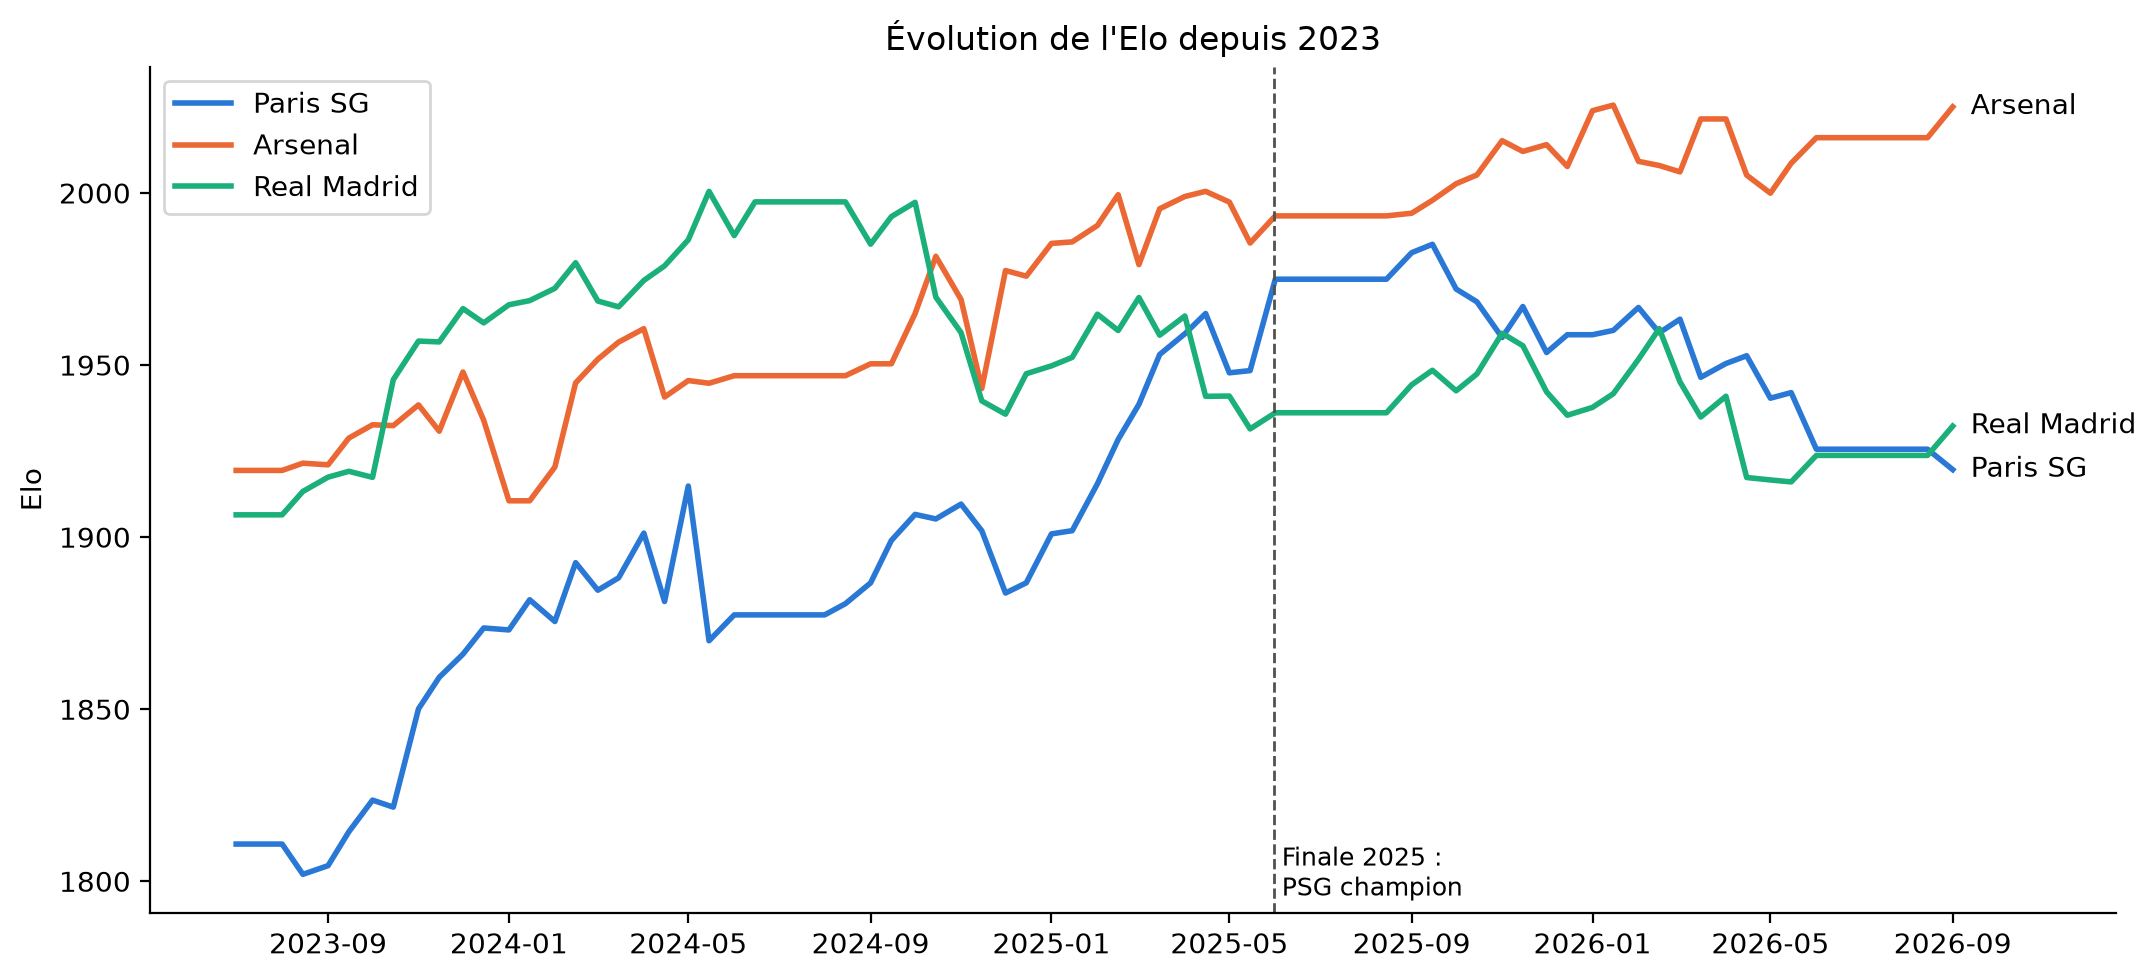

In [13]:
derniere_date = elo['date'].max()
top10 = elo[elo['date'] == derniere_date].nlargest(10, 'elo')[['club', 'elo']].reset_index(drop=True)
top10.index += 1
print(f"Top 10 Elo au {derniere_date.date()} :\n{top10.to_string()}")

clubs_suivis = {'Paris SG': BLEU, 'Arsenal': ORANGE, 'Real Madrid': VERT}
elo_recent = elo[elo['date'] >= '2023-07-01']
fig, ax = plt.subplots(figsize=(11, 5))
for club, couleur in clubs_suivis.items():
    serie = elo_recent[elo_recent['club'] == club]
    ax.plot(serie['date'], serie['elo'], color=couleur, linewidth=2, label=club)
    ax.text(serie['date'].iloc[-1], serie['elo'].iloc[-1], f"  {club}", va='center')
ax.axvline(pd.Timestamp('2025-05-31'), color='#52514e', linestyle='--', linewidth=1)
ax.text(pd.Timestamp('2025-05-31'), ax.get_ylim()[0] + 5, ' Finale 2025 :\n PSG champion', fontsize=9)
ax.set_xlim(right=elo_recent['date'].max() + pd.Timedelta(days=110))
ax.set_ylabel('Elo')
ax.set_title("Évolution de l'Elo depuis 2023")
ax.legend(loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 4. Qu'est-ce qui manque ? — Limites

- **Pas de données sur la saison à prédire :** aucun match de 2026-2027, et pas la finale 2025-2026. La liste des 36 clubs qualifiés devra venir d'une source externe (site de l'UEFA).
- **Elo incomplet :** 22 clubs sur 106 (Ukraine, Croatie, Suisse, Tchéquie…) n'ont pas d'Elo, soit 20 % des matchs. Nos analyses Elo portent donc surtout sur les grands championnats.
- **Elo imparfait :** il mélange championnat et Ligue des Champions (voir le cas du PSG).
- **Rien sur les joueurs :** pas de blessures, ni de compositions, ni de transferts. Or un effectif change chaque saison.
- **Petit échantillon pour la C1 :** 125 à 189 matchs par saison, et seulement 13 finales. Les phases finales, les plus importantes pour désigner le vainqueur, sont aussi les moins nombreuses.
- **Corrélation ≠ causalité :** nos analyses montrent des **liens** (Elo et victoire, public et avantage du terrain), pas des causes prouvées.

# 5. Conclusion

## 3 découvertes
1. **Le meilleur Elo gagne 56 % des matchs**, contre 48 % pour « l'équipe à domicile gagne ». Plus l'écart d'Elo est grand, plus le favori gagne (de 40 % à 79 %). C'est la **référence que notre modèle devra battre**.
2. **L'avantage du terrain disparaît sans public :** l'écart de buts tombe à 0,00 lors de la saison à huis clos (2020-2021).
3. **8 scores comptaient les tirs au but :** les corriger change le classement historique, puisque le Bayern passe devant le Real Madrid.

## 2 limites principales
1. **20 % des matchs n'ont pas d'Elo**, et aucun match de 2026-2027 n'est disponible.
2. **L'Elo mélange championnat et Ligue des Champions**, et pourrait sous-estimer des clubs comme le PSG.

## 1 question à poursuivre
> **L'Elo prédit-il aussi bien les matchs de Ligue des Champions que ceux de championnat ? Et faut-il le compléter par des indicateurs propres à la C1 (résultats européens récents, expérience, valeur de l'effectif) ?**

## Suite du projet
Construire les variables (écart d'Elo avant match, domicile, forme récente en C1), entraîner un modèle avec une **séparation chronologique** (entraînement 2012-2022, test 2023-2025), vérifier qu'il dépasse **56 %**, puis simuler la saison 2026-2027.